# 05 · H3: влияние объёма обучающих данных

**Гипотеза H3.** Качество моделей и их относительные преимущества зависят от размера обучающей выборки.

**Главный показатель:** Recall на неизменной test-выборке при пороге, выбранном на **validation** для Specificity ≥ 90%. Дополнительно рассматриваем pAUC (FPR ≤ 0.10), ROC AUC, AP и Brier score.

Этот эксперимент *не* подбирает гиперпараметры заново. Для каждого алгоритма используем **одну фиксированную конфигурацию из H1** при всех объёмах обучения. Так мы изолируем влияние количества данных от влияния настройки.

## 1. Импорты и окружение

Нужны существующие `src/data_generation.py`, `src/preprocessing.py`, `src/evaluation.py`, `src/plco.py` и `results/h1_selected_params.json` из H1.

In [3]:
from pathlib import Path
import json
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'src' / 'data_generation.py').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Запускайте ноутбук из корня проекта или папки notebooks/.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_generation import generate_baseline
from src.preprocessing import FEATURE_COLUMNS, make_preprocessor, split_dataset
from src.evaluation import select_threshold_at_specificity, evaluate_binary
from src.plco import plco_risk

print('Корень проекта:', PROJECT_ROOT)
print('Python:', sys.version.split()[0], '|', sys.executable)

Корень проекта: /Users/dyadyundanil/Documents/lung-cancer-ml-study
Python: 3.11.11 | /opt/anaconda3/envs/lung-cancer-ml/bin/python


## 2. Данные и фиксированные разбиения

Генерируем **одну** выборку S0 (`generate_baseline`). Оставляем 60% train, 20% validation и 20% test. Размер train будем изменять только **внутри исходного train**, не затрагивая validation/test. Зафиксируем список размеров до просмотра результатов.

При распространённости около 0,8% даже полный test из 10 000 человек содержит лишь ~80 положительных исходов. Поэтому сравнение является **разведочным**, а не окончательной проверкой устойчивости H3.

In [6]:
N = 50_000
DATA_SEED = 20261116  # Новая синтетическая генерация, отличная от H1
SPLIT_SEED = 1327
SUBSET_SEED = 2701
MODEL_SEED = 2026
MIN_SPECIFICITY = 0.90
TRAIN_SIZES = (5_000, 10_000, 20_000, 30_000)

patients = generate_baseline(n=N, seed=DATA_SEED)
splits = split_dataset(patients, val_fraction=0.20, test_fraction=0.20, seed=SPLIT_SEED)
assert list(splits.X_train.columns) == list(FEATURE_COLUMNS)
assert max(TRAIN_SIZES) <= len(splits.y_train)
assert len({*splits.X_train.index} & {*splits.X_val.index}) == 0
assert len({*splits.X_train.index} & {*splits.X_test.index}) == 0

split_summary = pd.DataFrame([
    {'Часть': 'Train', 'Пациентов': len(splits.y_train), 'Положительных': int(splits.y_train.sum())},
    {'Часть': 'Validation', 'Пациентов': len(splits.y_val), 'Положительных': int(splits.y_val.sum())},
    {'Часть': 'Test', 'Пациентов': len(splits.y_test), 'Положительных': int(splits.y_test.sum())},
])
display(split_summary)

,Часть,Пациентов,Положительных
0,Train,30000,248
1,Validation,10000,83
2,Test,10000,83


## 3. Вложенные стратифицированные обучающие подвыборки

Каждая следующая подвыборка включает все наблюдения предыдущей. Число положительных случаев возрастает пропорционально размеру train. Таким образом, при переходе от 5 000 к 30 000 мы **добавляем**, а не полностью заменяем пациентов.

Это уменьшает лишнюю вариабельность от изменения состава выборки. При этом на самых маленьких train положительных примеров всё равно мало.

In [9]:
def make_nested_train_indices(y_train, sizes, seed):
    y = np.asarray(y_train, dtype=int)
    if set(np.unique(y)) != {0, 1}:
        raise ValueError('Train должен содержать оба класса.')
    rng = np.random.default_rng(seed)
    positives = rng.permutation(np.flatnonzero(y == 1))
    negatives = rng.permutation(np.flatnonzero(y == 0))
    fraction_positive = float(np.mean(y))
    result = {}
    for size in sizes:
        n_pos = int(round(size * fraction_positive))
        n_neg = size - n_pos
        if n_pos < 2 or n_pos > len(positives) or n_neg > len(negatives):
            raise ValueError(f'Некорректный размер train: {size}')
        positions = np.concatenate((positives[:n_pos], negatives[:n_neg]))
        result[size] = np.sort(positions)
    for smaller, larger in zip(sizes, sizes[1:]):
        assert set(result[smaller]).issubset(set(result[larger]))
    return result

nested_indices = make_nested_train_indices(splits.y_train, TRAIN_SIZES, SUBSET_SEED)
subset_summary = pd.DataFrame([
    {'Train N': size,
     'Положительных train': int(splits.y_train.iloc[idx].sum()),
     'Доля y=1, %': 100 * splits.y_train.iloc[idx].mean()}
    for size, idx in nested_indices.items()
])
display(subset_summary.round(3))

,Train N,Положительных train,"Доля y=1, %"
0,5000,41,0.820
1,10000,83,0.830
2,20000,165,0.825
3,30000,248,0.827


## 4. Фиксированные гиперпараметры из H1

Загружаем `results/h1_selected_params.json`, который сохранил эксперимент №9. **Новый RandomizedSearchCV здесь не запускаем.** У каждой модели одинаковые гиперпараметры для всех размеров train. Предобработка (`StandardScaler`, `OneHotEncoder`) при каждом размере обучается заново исключительно на соответствующем train.

Если в H1 для модели была оставлена конфигурация по умолчанию, её словарь параметров пустой — это нормально.

In [12]:
config_path = PROJECT_ROOT / 'results' / 'h1_selected_params.json'
if not config_path.is_file():
    raise FileNotFoundError(
        'Не найден results/h1_selected_params.json из H1. '
        'Сначала сохраните результаты ноутбука 02_hyperparameter_tuning.ipynb.'
    )
with config_path.open(encoding='utf-8') as f:
    h1_config = json.load(f)
selected_parameters = h1_config['selected_parameters']

def pipeline(estimator):
    return Pipeline([
        ('preprocessor', make_preprocessor()),
        ('model', estimator),
    ])

model_templates = {
    'Logistic Regression': pipeline(LogisticRegression(max_iter=1000, random_state=MODEL_SEED)),
    'Random Forest': pipeline(RandomForestClassifier(random_state=MODEL_SEED, n_jobs=2)),
    'XGBoost': pipeline(XGBClassifier(
        objective='binary:logistic', eval_metric='logloss',
        tree_method='hist', n_jobs=2, random_state=MODEL_SEED,
    )),
    'MLP': pipeline(MLPClassifier(random_state=MODEL_SEED)),
}
assert set(selected_parameters) == set(model_templates), 'Список моделей в H1 и H3 не совпадает.'
for name, template in model_templates.items():
    template.set_params(**selected_parameters[name])

print('Фиксированные параметры из H1:')
for name in model_templates:
    print(f'  {name}: {selected_parameters[name] or "исходная конфигурация"}')

Фиксированные параметры из H1:
  Logistic Regression: {'model__C': 3.0}
  Random Forest: {'model__n_estimators': 120, 'model__min_samples_leaf': 15, 'model__max_features': 'sqrt', 'model__max_depth': None}
  XGBoost: {'model__subsample': 1.0, 'model__n_estimators': 100, 'model__min_child_weight': 1, 'model__max_depth': 3, 'model__learning_rate': 0.02, 'model__colsample_bytree': 1.0}
  MLP: {'model__learning_rate_init': 0.001, 'model__hidden_layer_sizes': [48], 'model__alpha': 0.1}


## 5. Обучение моделей и выбор порогов

Для каждого размера train обучаем заново все четыре модели. **Порог для каждой обученной модели выбираем на одном и том же validation** при Specificity ≥90%. На test применяем выбранный порог без перенастройки.

Обучения при разных размерах не независимы: train-подвыборки вложенные, а validation/test одни и те же. Предупреждения `ConvergenceWarning` от MLP не скрываем.

In [15]:
rows = []
probabilities_by_size = {}

for size, positions in nested_indices.items():
    X_sub = splits.X_train.iloc[positions]
    y_sub = splits.y_train.iloc[positions]
    print(f'\nTrain N={size:,}; положительных: {int(y_sub.sum())}')
    for name, template in model_templates.items():
        start = time.perf_counter()
        fitted = clone(template)
        fitted.fit(X_sub, y_sub)
        val_probs = fitted.predict_proba(splits.X_val)[:, 1]
        threshold = select_threshold_at_specificity(
            splits.y_val, val_probs, min_specificity=MIN_SPECIFICITY,
        )
        test_probs = fitted.predict_proba(splits.X_test)[:, 1]
        val_m = evaluate_binary(splits.y_val, val_probs, threshold=threshold)
        test_m = evaluate_binary(splits.y_test, test_probs, threshold=threshold)
        elapsed = time.perf_counter() - start
        probabilities_by_size[(size, name)] = test_probs
        ci = binomtest(test_m['tp'], test_m['positives']).proportion_ci(
            confidence_level=0.95, method='exact',
        )
        rows.append({
            'train_n': size, 'model': name,
            'train_positives': int(y_sub.sum()),
            'recall': test_m['recall'],
            'recall_ci_low': ci.low, 'recall_ci_high': ci.high,
            'specificity_test': test_m['specificity'],
            'specificity_val': val_m['specificity'],
            'pauc_std': test_m['pauc_standardized_fpr_0_10'],
            'roc_auc': test_m['roc_auc'],
            'ap': test_m['average_precision'],
            'brier': test_m['brier_score'],
            'tp': test_m['tp'], 'fp': test_m['fp'],
            'threshold': threshold, 'fit_seconds': elapsed,
        })
        print(f'  {name}: Recall={test_m["recall"]:.3f}, '
              f'Specificity(test)={test_m["specificity"]:.3f}, '
              f'pAUC={test_m["pauc_standardized_fpr_0_10"]:.3f}; '
              f'{elapsed:.1f} c')

results = pd.DataFrame(rows)
assert len(results) == len(TRAIN_SIZES) * len(model_templates)
assert (results['specificity_val'] >= MIN_SPECIFICITY - 1e-10).all()
display(results[['train_n', 'model', 'train_positives', 'recall',
                 'specificity_val', 'specificity_test', 'pauc_std',
                 'tp', 'fp']].round(4))


Train N=5,000; положительных: 41
  Logistic Regression: Recall=0.482, Specificity(test)=0.903, pAUC=0.634; 0.1 c
  Random Forest: Recall=0.410, Specificity(test)=0.895, pAUC=0.585; 0.3 c
  XGBoost: Recall=0.470, Specificity(test)=0.907, pAUC=0.614; 0.1 c
  MLP: Recall=0.446, Specificity(test)=0.905, pAUC=0.614; 0.5 c

Train N=10,000; положительных: 83
  Logistic Regression: Recall=0.554, Specificity(test)=0.907, pAUC=0.642; 0.0 c
  Random Forest: Recall=0.470, Specificity(test)=0.901, pAUC=0.607; 0.4 c
  XGBoost: Recall=0.458, Specificity(test)=0.903, pAUC=0.623; 0.1 c
  MLP: Recall=0.494, Specificity(test)=0.906, pAUC=0.629; 0.8 c

Train N=20,000; положительных: 165
  Logistic Regression: Recall=0.542, Specificity(test)=0.901, pAUC=0.657; 0.0 c
  Random Forest: Recall=0.446, Specificity(test)=0.898, pAUC=0.606; 0.6 c
  XGBoost: Recall=0.458, Specificity(test)=0.906, pAUC=0.622; 0.1 c
  MLP: Recall=0.518, Specificity(test)=0.903, pAUC=0.644; 1.4 c

Train N=30,000; положительных: 248
 

,train_n,model,train_positives,recall,specificity_val,specificity_test,pauc_std,tp,fp
0,5000,Logistic Regression,41,0.4819,0.9001,0.9027,0.6342,40,965
1,5000,Random Forest,41,0.4096,0.9001,0.8945,0.5854,34,1046
2,5000,XGBoost,41,0.4699,0.9055,0.9072,0.6138,39,920
3,5000,MLP,41,0.4458,0.9001,0.9049,0.6142,37,943
4,10000,Logistic Regression,83,0.5542,0.9001,0.9065,0.6422,46,927
5,10000,Random Forest,83,0.4699,0.9001,0.9013,0.6071,39,979
6,10000,XGBoost,83,0.4578,0.9006,0.9033,0.6229,38,959
7,10000,MLP,83,0.4940,0.9001,0.9060,0.6294,41,932
8,20000,Logistic Regression,165,0.5422,0.9001,0.9015,0.6572,45,977
9,20000,Random Forest,165,0.4458,0.9001,0.8985,0.6061,37,1007


## 6. Контрольная PLCOm2012

Эта модель не обучается, поэтому её прогнозы не зависят от объёма train. Для наглядности добавим горизонтальный ориентир при той же процедуре выбора порога на validation.

In [18]:
plco_val = splits.X_val.apply(plco_risk, axis=1).to_numpy()
plco_test = splits.X_test.apply(plco_risk, axis=1).to_numpy()
plco_threshold = select_threshold_at_specificity(
    splits.y_val, plco_val, min_specificity=MIN_SPECIFICITY,
)
plco_metrics = evaluate_binary(splits.y_test, plco_test, threshold=plco_threshold)
print('PLCOm2012: Recall(test)=', round(plco_metrics['recall'], 4),
      '| Specificity(test)=', round(plco_metrics['specificity'], 4),
      '| pAUC=', round(plco_metrics['pauc_standardized_fpr_0_10'], 4))

PLCOm2012: Recall(test)= 0.5422 | Specificity(test)= 0.9017 | pAUC= 0.6609


## 7. Кривые обучения: Recall — основной показатель

Линии строятся по **одним и тем же validation/test**. Рост размера train не гарантирует монотонного улучшения метрик на конечной тестовой выборке. Пунктир — PLCOm2012, не зависящая от обучения.

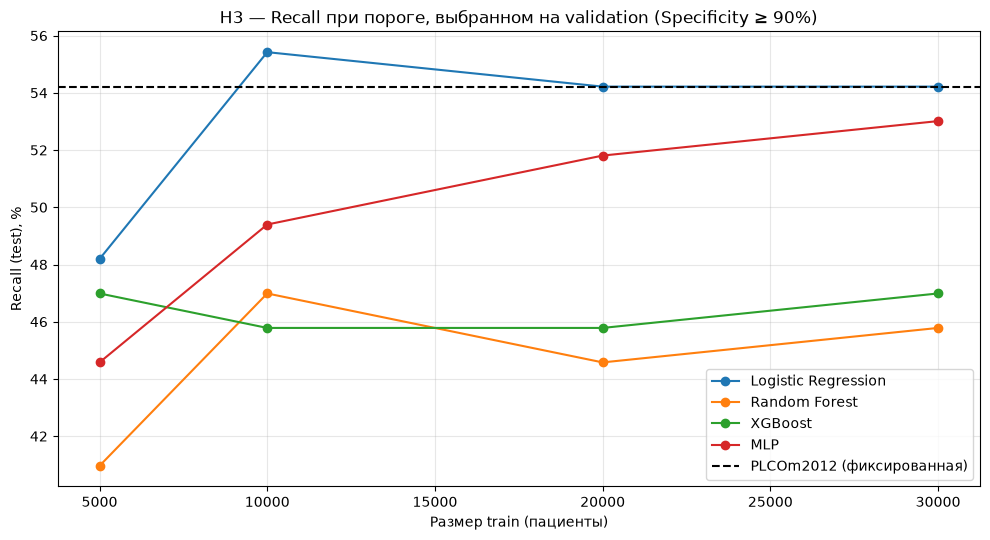

In [21]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for name, group in results.groupby('model', sort=False):
    group = group.sort_values('train_n')
    ax.plot(group['train_n'], 100 * group['recall'], marker='o', label=name)
ax.axhline(100 * plco_metrics['recall'], color='black', linestyle='--',
           linewidth=1.5, label='PLCOm2012 (фиксированная)')
ax.set(xlabel='Размер train (пациенты)', ylabel='Recall (test), %',
       title='H3 — Recall при пороге, выбранном на validation (Specificity ≥ 90%)')
ax.grid(alpha=0.3)
ax.legend(loc='best')
plt.tight_layout()
plt.show()

## 8. pAUC — дополнительная оценка качества ранжирования

Стандартизированная partial ROC AUC учитывает только диапазон FPR ≤0,10, то есть область высокой специфичности. Она **не заменяет** основную метрику Recall при выбранном пороге.

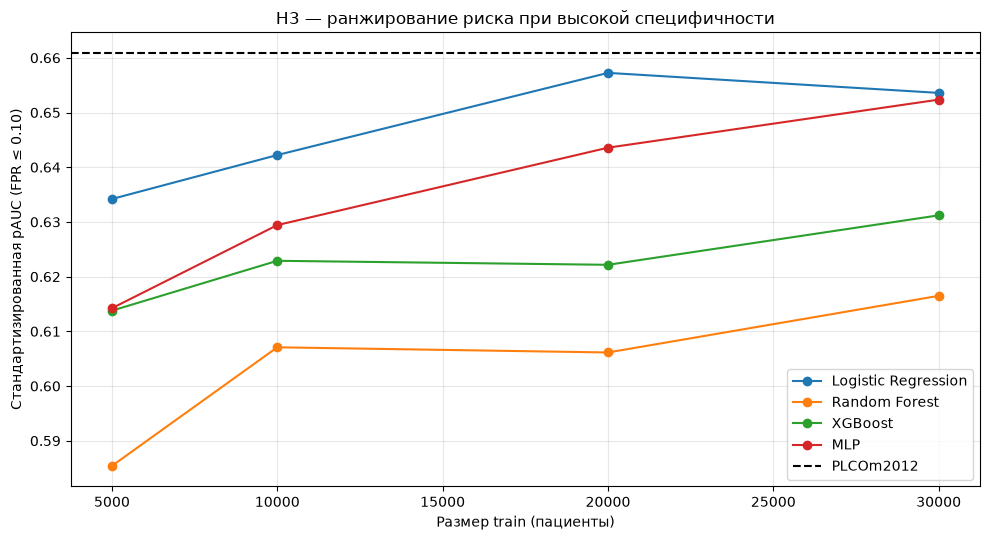

In [24]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for name, group in results.groupby('model', sort=False):
    group = group.sort_values('train_n')
    ax.plot(group['train_n'], group['pauc_std'], marker='o', label=name)
ax.axhline(plco_metrics['pauc_standardized_fpr_0_10'], color='black',
           linestyle='--', linewidth=1.5, label='PLCOm2012')
ax.set(xlabel='Размер train (пациенты)', ylabel='Стандартизированная pAUC (FPR ≤ 0.10)',
       title='H3 — ранжирование риска при высокой специфичности')
ax.grid(alpha=0.3)
ax.legend(loc='best')
plt.tight_layout()
plt.show()

## 9. Изменение качества от минимального к максимальному train

Это **описательные изменения на одном test**, а не статистическое доказательство преимущества той или иной модели. При ~80 положительных исходах один дополнительный TP меняет Recall примерно на 1,2 процентного пункта. Также сравниваем фактическую тестовую специфичность.

In [27]:
small = results[results['train_n'] == min(TRAIN_SIZES)].set_index('model')
large = results[results['train_n'] == max(TRAIN_SIZES)].set_index('model')
summary = pd.DataFrame({
    'Recall при min train, %': 100 * small['recall'],
    'Recall при max train, %': 100 * large['recall'],
    'Δ Recall, п.п.': 100 * (large['recall'] - small['recall']),
    'Δ pAUC': large['pauc_std'] - small['pauc_std'],
    'Specificity(test), min train': small['specificity_test'],
    'Specificity(test), max train': large['specificity_test'],
    'Δ TP': large['tp'] - small['tp'],
    'Δ FP': large['fp'] - small['fp'],
})
display(summary.round(4))
print('Положительных случаев в общем test:', int(splits.y_test.sum()))

,"Recall при min train, %","Recall при max train, %","Δ Recall, п.п.",Δ pAUC,"Specificity(test), min train","Specificity(test), max train",Δ TP,Δ FP
model,,,,,,,,
Logistic Regression,48.1928,54.2169,6.0241,0.0194,0.9027,0.9032,5,-5
Random Forest,40.9639,45.7831,4.8193,0.0311,0.8945,0.9033,4,-87
XGBoost,46.9880,46.9880,0.0000,0.0174,0.9072,0.9058,0,14
MLP,44.5783,53.0120,8.4337,0.0381,0.9049,0.9043,7,6


Положительных случаев в общем test: 83


## 10. Дополнительный эксперимент: повторная настройка на каждом размере train

**Вопрос:** изменится ли зависимость качества от размера выборки, если гиперпараметры выбирать заново для каждого объёма данных?

Для каждого сочетания «модель × размер train» применяем **3-fold Stratified CV только к соответствующей train-подвыборке**. Оптимизируем стандартизированную pAUC при FPR ≤ 0,10; исходная конфигурация также оценивается по той же CV и сохраняется, если не уступает найденной. После выбора параметров переобучаем модель на данной train-подвыборке, выбираем порог **только на неизменной validation** и оцениваем Recall на общем test.

Ускоренный поиск: **4 случайные конфигурации** для каждого алгоритма и размера (можно увеличить `TUNING_ITER` до 6). Пространства поиска соответствуют H1. Одни и те же случайные кандидаты используются для разных размеров train. Никакие параметры не выбираются по test.

**Ограничения:** на train=5 000 около 41 положительного случая, то есть в каждом CV-фолде положительных объектов мало. Настройка может быть нестабильной; сравнение нескольких вариантов на одном test — исследовательское, без автоматического вывода о статистической значимости. Предупреждения о сходимости MLP фиксируем, а не скрываем.

<!-- H3_RETRAIN_TUNING_V1 -->

In [30]:
from sklearn.metrics import make_scorer, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_score

TUNING_ITER = 4  # Быстрый режим; для сравнения с H1 можно задать 6.
TUNING_FOLDS = 3
TUNING_CV_SEED = 1729
TUNING_JOBS = 1   # Не включаем параллелизм нескольких поисков одновременно.

cv = StratifiedKFold(n_splits=TUNING_FOLDS, shuffle=True, random_state=TUNING_CV_SEED)
scorer = make_scorer(roc_auc_score, response_method='predict_proba', max_fpr=0.10)

# Те же семейства моделей и границы поиска, что и в H1.
search_spaces = {
    'Logistic Regression': {'model__C': [0.01, 0.03, 0.1, 0.3, 3.0, 10.0, 30.0]},
    'Random Forest': {
        'model__n_estimators': [120, 220, 320],
        'model__max_depth': [None, 8, 14],
        'model__min_samples_leaf': [2, 6, 15],
        'model__max_features': ['sqrt', 0.7],
    },
    'XGBoost': {
        'model__n_estimators': [100, 200, 320],
        'model__max_depth': [2, 3, 5],
        'model__learning_rate': [0.02, 0.05, 0.1],
        'model__min_child_weight': [1, 5, 15],
        'model__subsample': [0.8, 1.0],
        'model__colsample_bytree': [0.8, 1.0],
    },
    'MLP': {
        'model__hidden_layer_sizes': [(24,), (48,), (32, 16)],
        'model__alpha': [0.0001, 0.001, 0.01, 0.1],
        'model__learning_rate_init': [0.0005, 0.001, 0.003],
    },
}

# Важно: здесь используем исходные модели без фиксированных параметров из H1.
untuned_templates = {
    'Logistic Regression': pipeline(LogisticRegression(max_iter=1000, random_state=MODEL_SEED)),
    'Random Forest': pipeline(RandomForestClassifier(random_state=MODEL_SEED, n_jobs=2)),
    'XGBoost': pipeline(XGBClassifier(
        objective='binary:logistic', eval_metric='logloss',
        tree_method='hist', n_jobs=2, random_state=MODEL_SEED,
    )),
    'MLP': pipeline(MLPClassifier(random_state=MODEL_SEED)),
}
assert set(search_spaces) == set(untuned_templates)
print(f'Тюнинг: {TUNING_ITER} вариантов × {TUNING_FOLDS} CV-фолда, отдельно для каждого размера train.')

Тюнинг: 4 вариантов × 3 CV-фолда, отдельно для каждого размера train.


In [32]:
retuned_rows = []

for size, positions in nested_indices.items():
    X_sub = splits.X_train.iloc[positions]
    y_sub = splits.y_train.iloc[positions]
    assert int(y_sub.sum()) >= TUNING_FOLDS
    print(f'\n=== Train N={size:,}; положительных={int(y_sub.sum())} ===')
    for i, (name, initial_template) in enumerate(untuned_templates.items()):
        start = time.perf_counter()
        initial_cv = cross_val_score(
            clone(initial_template), X_sub, y_sub, cv=cv,
            scoring=scorer, n_jobs=TUNING_JOBS, error_score='raise',
        )
        search = RandomizedSearchCV(
            estimator=clone(initial_template),
            param_distributions=search_spaces[name],
            n_iter=TUNING_ITER,
            scoring=scorer, cv=cv,
            n_jobs=TUNING_JOBS,
            random_state=MODEL_SEED + i,  # Одинаковые кандидаты для всех размеров.
            refit=False, error_score='raise',
        )
        search.fit(X_sub, y_sub)
        keep_initial = float(initial_cv.mean()) >= float(search.best_score_)
        fitted = clone(initial_template)
        chosen_params = {} if keep_initial else search.best_params_
        if chosen_params:
            fitted.set_params(**chosen_params)
        fitted.fit(X_sub, y_sub)

        val_probs = fitted.predict_proba(splits.X_val)[:, 1]
        threshold = select_threshold_at_specificity(
            splits.y_val, val_probs, min_specificity=MIN_SPECIFICITY,
        )
        test_probs = fitted.predict_proba(splits.X_test)[:, 1]
        val_m = evaluate_binary(splits.y_val, val_probs, threshold=threshold)
        test_m = evaluate_binary(splits.y_test, test_probs, threshold=threshold)
        elapsed = time.perf_counter() - start
        retuned_rows.append({
            'train_n': size, 'model': name, 'train_positives': int(y_sub.sum()),
            'cv_pauc_initial': float(initial_cv.mean()),
            'cv_pauc_search': float(search.best_score_),
            'cv_pauc_selected': float(initial_cv.mean()) if keep_initial else float(search.best_score_),
            'selection': 'default' if keep_initial else 'tuned',
            'parameters': chosen_params,
            'recall': test_m['recall'],
            'specificity_val': val_m['specificity'],
            'specificity_test': test_m['specificity'],
            'pauc_std': test_m['pauc_standardized_fpr_0_10'],
            'roc_auc': test_m['roc_auc'],
            'ap': test_m['average_precision'],
            'brier': test_m['brier_score'],
            'tp': test_m['tp'], 'fp': test_m['fp'],
            'threshold': threshold, 'fit_seconds': elapsed,
        })
        print(f'  {name}: CV {initial_cv.mean():.4f} → '
              f'{retuned_rows[-1]["cv_pauc_selected"]:.4f}; '
              f'Recall(test)={test_m["recall"]:.3f}; '
              f'Specificity(test)={test_m["specificity"]:.3f}; {elapsed:.1f} c')

retuned = pd.DataFrame(retuned_rows)
assert len(retuned) == len(TRAIN_SIZES) * len(untuned_templates)
assert (retuned['specificity_val'] >= MIN_SPECIFICITY - 1e-10).all()
display(retuned[['train_n', 'model', 'train_positives', 'selection',
                 'cv_pauc_selected', 'recall', 'specificity_test', 'pauc_std',
                 'tp', 'fp']].round(4))


=== Train N=5,000; положительных=41 ===
  Logistic Regression: CV 0.6047 → 0.6095; Recall(test)=0.506; Specificity(test)=0.902; 0.2 c
  Random Forest: CV 0.5684 → 0.5942; Recall(test)=0.373; Specificity(test)=0.896; 5.3 c
  XGBoost: CV 0.5376 → 0.6023; Recall(test)=0.494; Specificity(test)=0.902; 0.7 c


/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  war

  MLP: CV 0.5236 → 0.5509; Recall(test)=0.422; Specificity(test)=0.907; 11.1 c

=== Train N=10,000; положительных=83 ===
  Logistic Regression: CV 0.6204 → 0.6205; Recall(test)=0.530; Specificity(test)=0.909; 0.3 c
  Random Forest: CV 0.5664 → 0.6231; Recall(test)=0.422; Specificity(test)=0.903; 8.0 c
  XGBoost: CV 0.5724 → 0.6002; Recall(test)=0.458; Specificity(test)=0.903; 0.9 c


/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  war

  MLP: CV 0.5776 → 0.5776; Recall(test)=0.301; Specificity(test)=0.902; 23.6 c

=== Train N=20,000; положительных=165 ===
  Logistic Regression: CV 0.6182 → 0.6194; Recall(test)=0.542; Specificity(test)=0.902; 0.4 c
  Random Forest: CV 0.5872 → 0.6101; Recall(test)=0.446; Specificity(test)=0.899; 14.4 c
  XGBoost: CV 0.5649 → 0.6129; Recall(test)=0.518; Specificity(test)=0.904; 1.5 c


/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  war

  MLP: CV 0.5819 → 0.6044; Recall(test)=0.446; Specificity(test)=0.905; 38.4 c

=== Train N=30,000; положительных=248 ===
  Logistic Regression: CV 0.6155 → 0.6164; Recall(test)=0.542; Specificity(test)=0.905; 0.4 c
  Random Forest: CV 0.5683 → 0.6096; Recall(test)=0.518; Specificity(test)=0.905; 21.6 c
  XGBoost: CV 0.5617 → 0.6083; Recall(test)=0.470; Specificity(test)=0.906; 1.9 c


/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  war

  MLP: CV 0.5724 → 0.6016; Recall(test)=0.494; Specificity(test)=0.906; 50.9 c


,train_n,model,train_positives,selection,cv_pauc_selected,recall,specificity_test,pauc_std,tp,fp
0,5000,Logistic Regression,41,tuned,0.6095,0.5060,0.9018,0.6381,42,974
1,5000,Random Forest,41,tuned,0.5942,0.3735,0.8961,0.5901,31,1030
2,5000,XGBoost,41,tuned,0.6023,0.4940,0.9021,0.6165,41,971
3,5000,MLP,41,tuned,0.5509,0.4217,0.9072,0.6055,35,920
4,10000,Logistic Regression,83,tuned,0.6205,0.5301,0.9088,0.6417,44,904
5,10000,Random Forest,83,tuned,0.6231,0.4217,0.9032,0.6087,35,960
6,10000,XGBoost,83,tuned,0.6002,0.4578,0.9033,0.6229,38,959
7,10000,MLP,83,default,0.5776,0.3012,0.9019,0.5586,25,973
8,20000,Logistic Regression,165,tuned,0.6194,0.5422,0.9018,0.6574,45,974
9,20000,Random Forest,165,tuned,0.6101,0.4458,0.8988,0.6117,37,1004


## 11. Сравнение кривых: фиксированные настройки H1 против настройки на каждом train

**Главная метрика — Recall на test**. Сплошные линии показывают новый повторный подбор, пунктирные — фиксированные настройки из H1, использованные в предыдущей части ноутбука. В обоих случаях validation/test одни и те же. Более высокая pAUC на train-CV **не гарантирует** повышения Recall на test.

,train_n,model,recall_fixed,recall_retuned,delta_recall_pp,specificity_test_retuned,pauc_std_fixed,pauc_std_retuned,delta_pauc
0,5000,Logistic Regression,0.4819,0.5060,2.4096,0.9018,0.6342,0.6381,0.0039
1,5000,Random Forest,0.4096,0.3735,-3.6145,0.8961,0.5854,0.5901,0.0047
2,5000,XGBoost,0.4699,0.4940,2.4096,0.9021,0.6138,0.6165,0.0027
3,5000,MLP,0.4458,0.4217,-2.4096,0.9072,0.6142,0.6055,-0.0087
4,10000,Logistic Regression,0.5542,0.5301,-2.4096,0.9088,0.6422,0.6417,-0.0005
5,10000,Random Forest,0.4699,0.4217,-4.8193,0.9032,0.6071,0.6087,0.0016
6,10000,XGBoost,0.4578,0.4578,0.0000,0.9033,0.6229,0.6229,0.0000
7,10000,MLP,0.4940,0.3012,-19.2771,0.9019,0.6294,0.5586,-0.0708
8,20000,Logistic Regression,0.5422,0.5422,0.0000,0.9018,0.6572,0.6574,0.0001
9,20000,Random Forest,0.4458,0.4458,0.0000,0.8988,0.6061,0.6117,0.0055


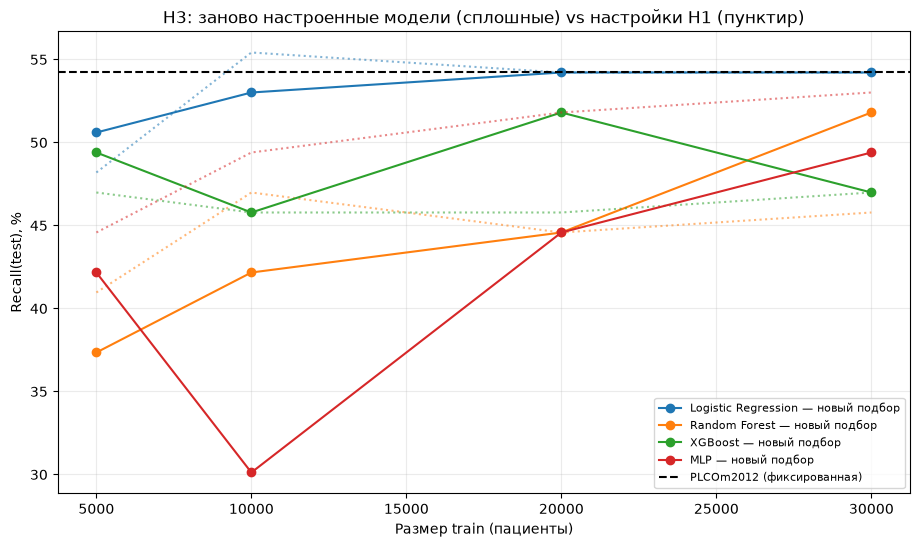

,"Recall 5k, %","Recall 30k, %","Δ Recall, п.п.",Δ pAUC
model,,,,
Logistic Regression,50.6024,54.2169,3.6145,0.0153
Random Forest,37.3494,51.8072,14.4578,0.0456
XGBoost,49.3976,46.9880,-2.4096,0.0147
MLP,42.1687,49.3976,7.2289,0.0304


Сохранены results/h3_retuned_metrics.csv и results/h3_fixed_vs_retuned.csv


In [35]:
comparison_h3 = retuned.merge(
    results[['train_n', 'model', 'recall', 'pauc_std', 'specificity_test', 'tp', 'fp']],
    on=['train_n', 'model'], suffixes=('_retuned', '_fixed'), validate='one_to_one',
)
comparison_h3['delta_recall_pp'] = 100 * (
    comparison_h3['recall_retuned'] - comparison_h3['recall_fixed']
)
comparison_h3['delta_pauc'] = comparison_h3['pauc_std_retuned'] - comparison_h3['pauc_std_fixed']
display(comparison_h3[['train_n', 'model', 'recall_fixed', 'recall_retuned',
                       'delta_recall_pp', 'specificity_test_retuned',
                       'pauc_std_fixed', 'pauc_std_retuned',
                       'delta_pauc']].round(4))

fig, ax = plt.subplots(figsize=(11, 6))
for name in untuned_templates:
    fixed = results[results['model'] == name].sort_values('train_n')
    tuned = retuned[retuned['model'] == name].sort_values('train_n')
    line, = ax.plot(tuned['train_n'], 100 * tuned['recall'],
                    marker='o', label=f'{name} — новый подбор')
    ax.plot(fixed['train_n'], 100 * fixed['recall'], linestyle=':',
            color=line.get_color(), alpha=.55)
ax.axhline(100 * plco_metrics['recall'], linestyle='--', color='black',
           label='PLCOm2012 (фиксированная)')
ax.set(xlabel='Размер train (пациенты)', ylabel='Recall(test), %',
       title='H3: заново настроенные модели (сплошные) vs настройки H1 (пунктир)')
ax.grid(alpha=.25)
ax.legend(loc='best', fontsize=8)
plt.show()

# Таблица итогового изменения для нового режима настройки.
first = retuned[retuned['train_n'] == min(TRAIN_SIZES)].set_index('model')
last = retuned[retuned['train_n'] == max(TRAIN_SIZES)].set_index('model')
tuned_growth = pd.DataFrame({
    'Recall 5k, %': 100 * first['recall'],
    'Recall 30k, %': 100 * last['recall'],
    'Δ Recall, п.п.': 100 * (last['recall'] - first['recall']),
    'Δ pAUC': last['pauc_std'] - first['pauc_std'],
})
display(tuned_growth.round(4))

# Файлы результатов сохраняем лишь после успешного завершения всех вариантов.
results_dir = PROJECT_ROOT / 'results'
results_dir.mkdir(exist_ok=True)
retuned.to_csv(results_dir / 'h3_retuned_metrics.csv', index=False, encoding='utf-8')
comparison_h3.to_csv(results_dir / 'h3_fixed_vs_retuned.csv', index=False, encoding='utf-8')
print('Сохранены results/h3_retuned_metrics.csv и results/h3_fixed_vs_retuned.csv')

## 12. Вывод по гипотезе H3

**Статус: гипотеза предварительно поддерживается данными.**

Эксперимент показал, что увеличение объёма обучающей выборки влияет на качество прогнозирования, однако характер изменений существенно зависит от алгоритма.

При повторном подборе гиперпараметров увеличение train с 5 000 до 30 000 пациентов повысило Recall у Random Forest на 14,46 п.п., у MLP — на 7,23 п.п., у Logistic Regression — на 3,61 п.п. Для XGBoost итогового улучшения Recall не обнаружено.

Logistic Regression продемонстрировала относительно высокое качество уже при небольшом объёме данных, тогда как Random Forest получила наиболее выраженный прирост с увеличением обучающей выборки.

Таким образом, результаты согласуются с H3, но не свидетельствуют о монотонном улучшении всех моделей при увеличении объёма данных. Вывод ограничен одним сценарием генерации, одной тестовой выборкой с 83 положительными случаями и предупреждениями о несходимости отдельных конфигураций MLP.